In [2]:
from pathlib import Path

# Search for the dataset in likely project locations
possible_paths = [
    Path("data/spacex_launches_clean.csv"),
    Path("SpaceX_Capstone/data/spacex_launches_clean.csv"),
    Path("../data/spacex_launches_clean.csv"),
    Path("../SpaceX_Capstone/data/spacex_launches_clean.csv"),
]

data_file = next(
    (p.resolve() for p in possible_paths if p.exists()),
    None
)

if data_file is None:
    print("Dataset not found in the expected locations.")
    print("Current working directory:", Path.cwd())
    print("\nCSV files in the current directory and subfolders:")

    for p in Path.cwd().rglob("*.csv"):
        print(p)
else:
    print("Dataset found at:", data_file)

Dataset found at: C:\Users\acer\OneDrive\Desktop\capstone\SpaceX_Capstone\.venv\notebooks\data\spacex_launches_clean.csv


In [3]:
import pandas as pd

df = pd.read_csv(data_file)

print("Dataset shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nLanding outcomes:")
print(df["Outcome"].value_counts(dropna=False))

display(df.head())

Dataset shape: (90, 17)

Available columns:
['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']

Landing outcomes:
Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,NaN,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.0,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.0,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.0,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.0,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857


In [4]:
print(df["Outcome"].value_counts(dropna=False))

Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64


In [5]:
print(df["Outcome"].value_counts(dropna=False))

Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64


In [6]:
# 1 = successful landing; 0 = unsuccessful or other outcome
df["LandingSuccess"] = (
    df["Outcome"]
    .fillna("")
    .astype(str)
    .str.startswith("True")
    .astype(int)
)

print("Target variable created!")
print(df["LandingSuccess"].value_counts())

Target variable created!
LandingSuccess
1    60
0    30
Name: count, dtype: int64


In [7]:
display(
    df.groupby("Outcome")["LandingSuccess"]
    .agg(["count", "first"])
)

,count,first
Outcome,,
False ASDS,6,0
False Ocean,2,0
False RTLS,1,0
None ASDS,2,0
None None,19,0
True ASDS,41,1
True Ocean,5,1
True RTLS,14,1


In [8]:
# Check that our target exists
print("Target column exists:", "LandingSuccess" in df.columns)

# Select the input features available in your dataset
candidate_features = [
    "PayloadMass",
    "Flights",
    "GridFins",
    "Reused",
    "Legs",
    "Block",
    "ReusedCount",
    "Orbit",
    "LaunchSite"
]

features = [col for col in candidate_features if col in df.columns]

print("Selected features:", features)

Target column exists: True
Selected features: ['PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Orbit', 'LaunchSite']


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Keep only the required columns
model_df = df[features + ["LandingSuccess"]].copy()

# Separate inputs and target
X = model_df[features]
y = model_df["LandingSuccess"]

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include="number").columns.tolist()
categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("\nTarget distribution:")
print(y.value_counts())

Numeric features: ['PayloadMass', 'Flights', 'Block', 'ReusedCount']
Categorical features: ['GridFins', 'Reused', 'Legs', 'Orbit', 'LaunchSite']

Target distribution:
LandingSuccess
1    60
0    30
Name: count, dtype: int64


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training target distribution:")
print(y_train.value_counts())

Training records: 72
Testing records: 18
Training target distribution:
LandingSuccess
1    48
0    24
Name: count, dtype: int64


In [11]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Process numeric columns
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Process categorical columns
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_features),
    ("categorical", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Support Vector Machine": SVC(),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5)
}

results = []
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, predictions, zero_division=0
        )
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "F1 Score", ascending=False
)

display(results_df.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
3,K-Nearest Neighbors,0.833,0.800,1.000,0.889
2,Decision Tree,0.833,0.846,0.917,0.880
1,Support Vector Machine,0.778,0.750,1.000,0.857
0,Logistic Regression,0.778,0.750,1.000,0.857


In [14]:
from pathlib import Path

output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    output_dir / "model_comparison.csv",
    index=False
)

print("Model comparison saved to:", output_dir.resolve())

Model comparison saved to: C:\Users\acer\OneDrive\Desktop\capstone\SpaceX_Capstone\.venv\notebooks\data\results


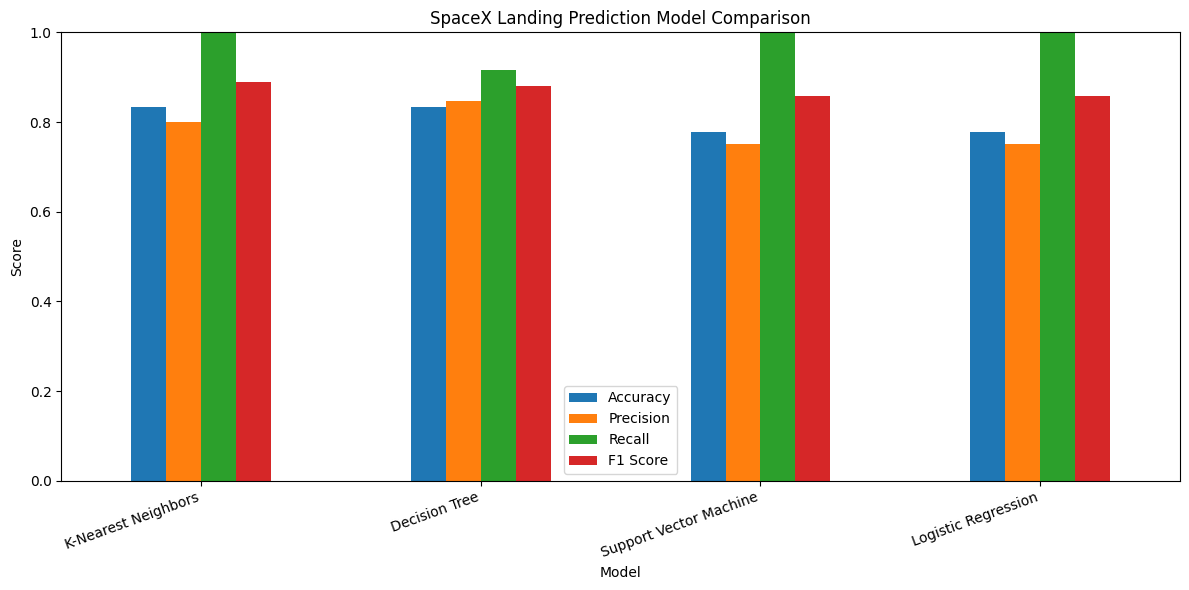

Model comparison chart saved!


In [15]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("results")
output_dir.mkdir(parents=True, exist_ok=True)

results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1 Score"]
].plot(kind="bar", figsize=(12, 6))

plt.title("SpaceX Landing Prediction Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()

plt.savefig(
    output_dir / "model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Model comparison chart saved!")

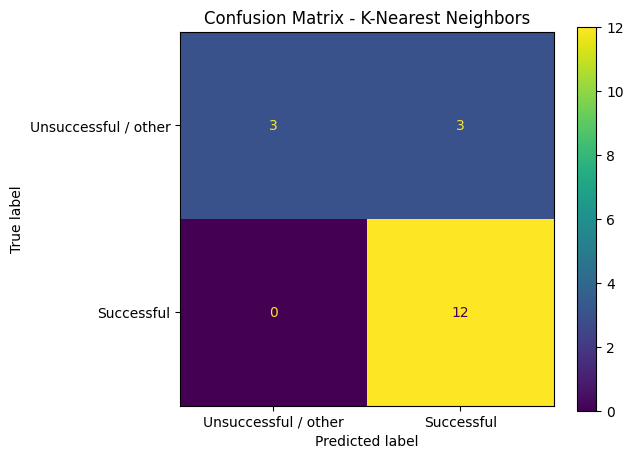

Confusion matrix saved!


: 

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    display_labels=["Unsuccessful / other", "Successful"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()

plt.savefig(
    output_dir / "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrix saved!")